# Accent-dependent acoustic features and Whisper WER: statistical analysis

**Research question:** To what extent do accent-dependent variations in acoustic speech features across African-accented English relate to transcription performance, measured using WER, in a pre-trained ASR model compared to a standard baseline?

| Section | What it does | In the report |
|---|---|---|
| 1 | File paths and settings | – |
| 2 | Load, merge and clean the data (only recordings present in **every** file are kept) | Methods |
| 3 | Build the acoustic descriptors | Methods |
| 4 | z-scores against same-gender American speakers (leave-one-out) | Methods |
| 5 | **Stage 1:** which descriptors are accent-dependent (Mann–Whitney, Cliff's δ, Benjamini–Hochberg): full list of descriptors and the ones kept | Results |
| 6 | Check for differences between the African L1 groups | Methods (one sentence) |
| 7 | Distance from the American baseline per feature | Methods |
| 8 | **Stage 2:** distance vs WER (Spearman ρ, bootstrap CI, BH) per group, incl. AfriSpeech | Main results |
| 9 | Speech rate vs non-rate vs both (share of WER explained) | Results |
| 10 | Same-speaking-rate comparison (does rate explain the African–American gap?) | Results |
| A1 | Appendix: direction of each descriptor vs WER | Appendix |
| A2 | Appendix: pooled SAA correlation accounting for accent group | Appendix |

All tables are saved as CSV files and all figures as PNG files in the output folder set in Section 1.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

## 1. File paths and settings

**Fill in the paths below.** The transcriptions file is not needed since `scored.csv` already contains the WER, substitutions, deletions, insertions and number of reference words.

In [2]:
RESULTS_ROOT = Path("../results/")

PATHS = {
    'manifest':     RESULTS_ROOT / 'dsp/runs/analysis_full/pitch/manifest_snapshot.csv',
    'scored':       RESULTS_ROOT / 'asr/runs/analysis_base_long/scored.csv',
    'mfcc':         RESULTS_ROOT / 'dsp/runs/analysis_full/mfcc/features.csv',
    'pitch':        RESULTS_ROOT / 'dsp/runs/analysis_full/pitch/features.csv',
    'speech_rate':  RESULTS_ROOT / 'dsp/runs/analysis_full/speech_rate_reference/features.csv',   # the reference-transcript rate file (rate_ref_* columns)
    'formants':     RESULTS_ROOT / 'dsp/runs/analysis_full/formants/features.csv',
}
OUTPUT_DIR = 'analysis_outputs'          # tables (CSV) and figures (PNG) are written here

# Recordings excluded by decision (transcription or feature outliers)
EXCLUDE_IDS = [
    'afrispeech_c74590e7e899b82d38a0599414907577',
    'afrispeech_ad2ddb8a0a31e06e12f2065866c4588e',
    'afrispeech_03bcfda67aaa67be96d4e44acadf3615',
    'afrispeech_12db0516db3e30de0d08e6eb0cb42370',
]

# Implausible F1 tracks (the tracker followed F2): removed if any F1 p90 > 1500 Hz or F1 median > 900 Hz
F1_P90_MAX_HZ = 1500
F1_MEDIAN_MAX_HZ = 900

# Accent groups
AMERICAN_LABEL = 'american_english'
HINDI_LABEL = 'hindi'
AFRICAN_L1S = ['amharic', 'hausa', 'kiswahili', 'tigrigna', 'yoruba']
AFRISPEECH_DATASET = 'afrispeech'
SAA_DATASET = 'saa'

# Statistical settings
Q_THRESHOLD = 0.05        # Benjamini–Hochberg false discovery rate
DELTA_THRESHOLD = 0.33    # |Cliff's delta| >= 0.33 = at least a medium effect (Romano et al., 2006)
N_BOOT = 2000             # bootstrap resamples for 95% confidence intervals
SEED = 42                 # makes the bootstrap reproducible

# Same-speaking-rate bands (speaking-rate z-score vs same-gender American speakers)
RATE_BANDS = [(-2.5, -0.5), (-2.0, -1.0), (-2.5, -1.5), (-1.8, -0.8)]

COLORS = {'American': '#2a78d6', 'Hindi': '#1b9e70', 'African': '#e0632f', 'AfriSpeech': '#7b5ea7'}
FIG_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

def save(df, name, index=False):
    df.to_csv(os.path.join(OUTPUT_DIR, name), index=index)

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches='tight')

In [3]:
# Display helpers: every table is shown in the notebook as a formatted, captioned table (and also saved as CSV)
from IPython.display import display, Markdown
TABLE_CSS = [dict(selector='caption', props=[('caption-side', 'top'), ('text-align', 'left'), ('padding-bottom', '6px')])]
def show(df, title, note=None, formats=None, index=False, row_style=None):
    sty = df.style.set_caption(f'<b>{title}</b>').set_table_styles(TABLE_CSS).format(formats or {}, na_rep='–')
    if not index:
        sty = sty.hide(axis='index')
    if row_style is not None:
        sty = sty.apply(row_style, axis=1)
    display(sty)
    if note:
        display(Markdown(f'<span style="font-size:0.9em">{note}</span>'))
def pfmt(p):
    return '<0.001' if p < 0.001 else f'{p:.3f}'
FIGS = {}   # figures kept here so they can be shown again in the report summary at the end

## 2. Load, merge and clean the data

Each file is loaded, rows that failed processing (`status != 'ok'`) are dropped, and only recordings present in **all six files** (manifest, scored, MFCC, pitch, speech rate, formants) are kept. This means every analysis uses exactly the same recordings.

Two further removals follow:
1. **Implausible F1 tracks**: F1 values that are physically impossible for F1 (the tracker followed F2).
2. **Manual exclusions**: the four AfriSpeech recordings with broken transcriptions.

In [4]:
META_COLS = ['dataset', 'manifest_index', 'status', 'error_type', 'error_message', 'feature_name',
             'feature_version', 'processed_duration_s', 'elapsed_s', 'completed_at_utc']

REQUIRED = {
    'manifest':    ['sample_id', 'dataset', 'accent_group', 'sex'],
    'scored':      ['sample_id', 'wer', 'substitutions', 'deletions', 'insertions', 'n_reference_words'],
    'mfcc':        ['sample_id'] + [f'mfcc_{i:02d}_{k}' for i in range(1, 13) for k in ('mean', 'std')],
    'pitch':       ['sample_id', 'f0_median_hz', 'f0_span_st', 'f0_p10_hz', 'f0_p90_hz'],
    'speech_rate': ['sample_id', 'rate_ref_speaking_syl_per_s', 'rate_ref_articulation_syl_per_s', 'rate_pause_fraction'],
    'formants':    ['sample_id'] + [f'f{k}_{pre}{q}_hz' for k in (1, 2, 3) for pre in ('', 'loud_half_') for q in ('median', 'p10', 'p90')],
}

def load(name):
    path = PATHS[name]
    if not os.path.exists(path):
        raise FileNotFoundError(f'{name}: file not found at {path!r}. Update PATHS in Section 1.')
    df = pd.read_csv(path)
    missing = [c for c in REQUIRED[name] if c not in df.columns]
    if missing:
        raise ValueError(f'{name}: missing columns {missing}')
    n_rows = len(df)
    for status_col in ('status', 'scoring_status', 'transcription_status'):
        if status_col in df.columns:
            df = df[df[status_col] == 'ok']
    df = df.dropna(subset=REQUIRED[name]).drop_duplicates('sample_id')
    return df, n_rows

raw, load_log = {}, []
for name in PATHS:
    df, n_rows = load(name)
    raw[name] = df
    load_log.append(dict(file=name, rows_in_file=n_rows, usable_rows=len(df)))

common_ids = set.intersection(*[set(df.sample_id) for df in raw.values()])
for row in load_log:
    row['missing_from_this_file'] = len(set().union(*[set(df.sample_id) for df in raw.values()]) - set(raw[row['file']].sample_id))
load_log = pd.DataFrame(load_log)
show(load_log, 'Rows per input file', note='Usable = status ok and no missing values in the required columns.')
print(f'Recordings present in all files: {len(common_ids)}')

file,rows_in_file,usable_rows,missing_from_this_file
manifest,546,546,34
scored,580,580,0
mfcc,580,580,0
pitch,546,546,34
speech_rate,546,546,34
formants,546,542,38


<span style="font-size:0.9em">Usable = status ok and no missing values in the required columns.</span>

Recordings present in all files: 542


In [5]:
# Merge everything on sample_id (inner join = only recordings present in every file)
d = raw['manifest'][REQUIRED['manifest']].copy()
d = d.merge(raw['scored'][REQUIRED['scored']], on='sample_id')
for name in ['mfcc', 'pitch', 'speech_rate', 'formants']:
    df = raw[name]
    d = d.merge(df.drop(columns=[c for c in META_COLS if c in df.columns]), on='sample_id')
d['sex'] = d['sex'].str.lower().str.strip()
excl_log = [('Present in all six files', len(d))]

# Implausible F1 tracks
bad_f1 = ((d[['f1_p90_hz', 'f1_loud_half_p90_hz']].max(axis=1) > F1_P90_MAX_HZ) |
          (d[['f1_median_hz', 'f1_loud_half_median_hz']].max(axis=1) > F1_MEDIAN_MAX_HZ))
print('Removed for implausible F1 track:', d.loc[bad_f1, 'sample_id'].tolist())
d = d[~bad_f1]
excl_log.append(('After removing implausible F1 tracks', len(d)))

# Manual exclusions
print('Removed by manual exclusion:', d.loc[d.sample_id.isin(EXCLUDE_IDS), 'sample_id'].tolist())
d = d[~d.sample_id.isin(EXCLUDE_IDS)].reset_index(drop=True)
excl_log.append(('After manual AfriSpeech exclusions', len(d)))

# Accent groups
def assign_group(r):
    if r.dataset == AFRISPEECH_DATASET: return 'AfriSpeech'
    if r.dataset == SAA_DATASET and r.accent_group == AMERICAN_LABEL: return 'American'
    if r.dataset == SAA_DATASET and r.accent_group == HINDI_LABEL: return 'Hindi'
    if r.dataset == SAA_DATASET and r.accent_group in AFRICAN_L1S: return 'African'
    return 'Other'
d['group'] = d.apply(assign_group, axis=1)
if (d.group == 'Other').any():
    print('Recordings not in any analysis group (dropped):', d.loc[d.group == 'Other', ['sample_id', 'dataset', 'accent_group']].values.tolist())
    d = d[d.group != 'Other'].reset_index(drop=True)
    excl_log.append(('After dropping recordings outside the analysis groups', len(d)))

excl_log = pd.DataFrame(excl_log, columns=['step', 'recordings'])
excl_log.insert(0, 'start (manifest rows)', len(raw['manifest']))
save(excl_log, '01_exclusions.csv')
show(excl_log, 'Recordings remaining after each cleaning step')

GROUPS = ['American', 'Hindi', 'African', 'AfriSpeech']
G = d.group.values; W = d.wer.values
MASK = {g: (G == g) for g in GROUPS}
SAA = d.dataset.eq(SAA_DATASET).values
Am, Hi, Af, AS = MASK['American'], MASK['Hindi'], MASK['African'], MASK['AfriSpeech']

overview = (d.groupby('group').agg(speakers=('sample_id', 'size'), women=('sex', lambda s: (s == 'female').sum()),
                                   men=('sex', lambda s: (s == 'male').sum())).reindex(GROUPS))
overview['L1 / accent composition'] = [', '.join(f'{k} {v}' for k, v in d[d.group == g].accent_group.value_counts().items()) for g in GROUPS]
save(overview, '02_sample_overview.csv', index=True)
show(overview, 'Speakers per analysis group', index=True)

Removed for implausible F1 track: ['saa_english336', 'saa_english469', 'saa_english49']
Removed by manual exclusion: ['afrispeech_03bcfda67aaa67be96d4e44acadf3615', 'afrispeech_12db0516db3e30de0d08e6eb0cb42370', 'afrispeech_ad2ddb8a0a31e06e12f2065866c4588e', 'afrispeech_c74590e7e899b82d38a0599414907577']


start (manifest rows),step,recordings
546,Present in all six files,542
546,After removing implausible F1 tracks,539
546,After manual AfriSpeech exclusions,535


,speakers,women,men,L1 / accent composition
group,,,,
American,306,148,158,american_english 306
Hindi,18,10,8,hindi 18
African,46,22,24,"amharic 18, hausa 9, kiswahili 7, tigrigna 7, yoruba 5"
AfriSpeech,165,100,65,"yoruba 95, kiswahili 44, hausa 26"


## 3. Acoustic descriptors

Each feature is summarised per recording by a few **descriptors**:

| Feature | Descriptors |
|---|---|
| Speech rate | speaking rate, articulation rate, pause fraction |
| Pitch (F0) | median (Hz), full span (st), lower span = 12·log2(median/p10), upper span = 12·log2(p90/median) |
| MFCC | mean and SD of c1–c12 (c0, overall loudness, is excluded) |
| F1, F2, F3 | median, range (p90 − p10), lower span (median − p10), upper span (p90 − median), for both the **louder-half** (LH) and **all-voiced** (AV) frame selections |

This gives 55 candidate descriptors in total (3 + 4 + 24 + 24).

In [6]:
st = lambda a, b: 12 * np.log2(a / b)   # semitone difference
FAM = {
    'Rate':  {'speaking rate': d.rate_ref_speaking_syl_per_s,
              'articulation rate': d.rate_ref_articulation_syl_per_s,
              'pause fraction': d.rate_pause_fraction},
    'Pitch': {'F0 median': d.f0_median_hz, 'F0 full span': d.f0_span_st,
              'F0 lower span': st(d.f0_median_hz, d.f0_p10_hz), 'F0 upper span': st(d.f0_p90_hz, d.f0_median_hz)},
    'MFCC':  {f'c{i} {k}': d[f'mfcc_{i:02d}_{k}'] for i in range(1, 13) for k in ('mean', 'std')},
}
for k in (1, 2, 3):
    FAM[f'F{k}'] = {}
    for tag, pre in (('LH', 'loud_half_'), ('AV', '')):
        g = lambda q: d[f'f{k}_{pre}{q}_hz']
        FAM[f'F{k}'].update({f'{tag} F{k} median': g('median'), f'{tag} F{k} range': g('p90') - g('p10'),
                             f'{tag} F{k} lower span': g('median') - g('p10'), f'{tag} F{k} upper span': g('p90') - g('median')})
X = pd.DataFrame({c: v for f in FAM.values() for c, v in f.items()})
DESC2FEAT = {c: f for f, cols in FAM.items() for c in cols}
print(f'{X.shape[1]} candidate descriptors for {len(X)} recordings')

55 candidate descriptors for 535 recordings


## 4. z-scores against the American baseline (same gender, leave-one-out)

Every descriptor is converted to a z-score: **z = (value − American mean) / American SD**, using American SAA speakers **of the same gender** as the reference.

For an American speaker, that speaker is **left out** of their own reference (leave-one-out), so they are not compared partly against themselves. Hindi, African and AfriSpeech speakers are compared with all American speakers of their gender.

In [7]:
Z = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)
for sx in ('male', 'female'):
    m = (d.sex == sx).values
    ref = Am & m                                   # same-gender American reference
    for c in X.columns:
        v = X[c].values.astype(float)
        n, S, SS = ref.sum(), v[ref].sum(), (v[ref] ** 2).sum()
        mu = np.full(len(v), S / n)
        var = np.full(len(v), (SS - S ** 2 / n) / (n - 1))
        # leave-one-out for the American reference speakers themselves
        mu[ref] = (S - v[ref]) / (n - 1)
        var[ref] = ((SS - v[ref] ** 2) - (S - v[ref]) ** 2 / (n - 1)) / (n - 2)
        Z.loc[m, c] = ((v - mu) / np.sqrt(var))[m]

ref_info = pd.DataFrame({sx: {'American reference speakers': int((Am & (d.sex == sx).values).sum()),
                              'American mean F0 (Hz)': X.loc[Am & (d.sex == sx).values, 'F0 median'].mean(),
                              'American mean speaking rate (syl/s)': X.loc[Am & (d.sex == sx).values, 'speaking rate'].mean()}
                         for sx in ('female', 'male')})
show(ref_info, 'Same-gender American reference', index=True, formats='{:.2f}')

,female,male
American reference speakers,148.00,158.00
American mean F0 (Hz),197.06,115.32
American mean speaking rate (syl/s),3.62,3.62


## 5. Stage 1: which descriptors are accent-dependent? (WER is not used)

For each of the 55 descriptors, African and American SAA speakers are compared with a **Mann–Whitney U test**. Its p-value answers "could this difference be luck?" and **Cliff's δ** measures how big the difference is (−1 to +1; (δ + 1)/2 is the chance that a random African speaker has the higher value). Hindi vs American is computed in the same way for comparison.

p-values are corrected for testing 55 descriptors with **Benjamini–Hochberg** (q-values).

**Selection rule:** a descriptor is accent-dependent if **q < 0.05 and |δ| ≥ 0.33** (African vs American).

For formants, the louder-half (LH) and all-voiced (AV) versions measure the same thing, so only one set is used. The set that better separates African from American speakers (cross-validated logistic-regression AUC) is chosen; this also does not use WER.

The first table lists **every** descriptor with its δ, p and q and whether it was kept; the second shows only the kept descriptors (the table for the report).

In [8]:
def cliff(a, b):
    # Cliff's delta and the Mann–Whitney p-value. delta = P(a > b) - P(a < b)
    u = stats.mannwhitneyu(a, b, alternative='two-sided')
    return 2 * u.statistic / (len(a) * len(b)) - 1, u.pvalue

rows = []
for c in X.columns:
    dl, p = cliff(Z.loc[Af, c], Z.loc[Am, c])
    dh, ph = cliff(Z.loc[Hi, c], Z.loc[Am, c])
    rows.append(dict(feature=DESC2FEAT[c], descriptor=c, delta_Af_Am=dl, p_Af_Am=p, delta_Hi_Am=dh, p_Hi_Am=ph))
S1 = pd.DataFrame(rows)
S1['q_Af_Am'] = multipletests(S1.p_Af_Am, method='fdr_bh')[1]
S1['q_Hi_Am'] = multipletests(S1.p_Hi_Am, method='fdr_bh')[1]
S1['passes_rule'] = (S1.q_Af_Am < Q_THRESHOLD) & (S1.delta_Af_Am.abs() >= DELTA_THRESHOLD)

# Formant frame selection (LH vs AV) by separation only.
# Cross-validated logistic regression: how well do all 12 LH (or all 12 AV) formant descriptors
# together tell African from American speakers? The better-separating frame selection is used.
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced', C=0.3))
def clf_auc(cols, A=Af, B=Am, reps=10):
    mm = A | B; y = A[mm].astype(int); Xm = Z.loc[mm, cols].values; out = []
    for s in range(reps):
        score = np.zeros(len(y))
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=s).split(Xm, y):
            clf.fit(Xm[tr], y[tr]); score[te] = clf.decision_function(Xm[te])
        out.append(roc_auc_score(y, score))
    return np.mean(out)
formant_cols = [c for k in (1, 2, 3) for c in FAM[f'F{k}']]
auc_LH = clf_auc([c for c in formant_cols if c.startswith('LH')])
auc_AV = clf_auc([c for c in formant_cols if c.startswith('AV')])
FRAME = 'LH' if auc_LH >= auc_AV else 'AV'
print(f'Formant frame selection: LH AUC = {auc_LH:.3f}, AV AUC = {auc_AV:.3f} -> use {FRAME}')

is_formant = S1.feature.isin(['F1', 'F2', 'F3'])
S1['candidate'] = ~is_formant | S1.descriptor.str.startswith(FRAME)
S1['selected'] = S1.passes_rule & S1.candidate
save(S1, '05_stage1_all_descriptors.csv')

cand = S1[S1.candidate]
print(f'\nCandidates after frame choice: {len(cand)}  |  q < 0.05: {(cand.q_Af_Am < Q_THRESHOLD).sum()}  |  '
      f'|delta| >= {DELTA_THRESHOLD}: {(cand.delta_Af_Am.abs() >= DELTA_THRESHOLD).sum()}  |  both (selected): {cand.selected.sum()}')

SEL = {f: S1[(S1.feature == f) & S1.selected].descriptor.tolist() for f in FAM}
SEL = {f: v for f, v in SEL.items() if v}
FEATS = list(SEL)
for f, v in SEL.items(): print(f'  {f}: {v}')

Formant frame selection: LH AUC = 0.894, AV AUC = 0.863 -> use LH

Candidates after frame choice: 43  |  q < 0.05: 25  |  |delta| >= 0.33: 14  |  both (selected): 14
  Rate: ['speaking rate', 'articulation rate']
  Pitch: ['F0 full span']
  MFCC: ['c2 mean', 'c3 std', 'c4 std', 'c8 mean']
  F1: ['LH F1 median', 'LH F1 range', 'LH F1 lower span']
  F2: ['LH F2 range', 'LH F2 lower span', 'LH F2 upper span']
  F3: ['LH F3 lower span']


In [9]:
# Full list of all descriptors: Cliff's delta, p and q (African vs American, and Hindi vs American), and the decision
def mag(x):
    a = abs(x)
    return 'large' if a >= 0.474 else 'medium' if a >= 0.33 else 'small' if a >= 0.147 else 'negligible'
def status(r):
    if not r.candidate: return f'not used ({"AV" if FRAME == "LH" else "LH"} frames)'
    if r.selected: return 'KEPT'
    if r.q_Af_Am >= Q_THRESHOLD: return 'dropped: q >= 0.05'
    return f'dropped: |delta| < {DELTA_THRESHOLD}'
full = S1.assign(size=S1.delta_Af_Am.map(mag), decision=S1.apply(status, axis=1))
table_full = full[['feature', 'descriptor', 'delta_Af_Am', 'size', 'p_Af_Am', 'q_Af_Am', 'delta_Hi_Am', 'p_Hi_Am', 'q_Hi_Am', 'decision']]
save(table_full, 'TABLE1a_stage1_all_descriptors.csv')
t1a = table_full.rename(columns={'feature': 'Feature', 'descriptor': 'Descriptor', 'delta_Af_Am': 'δ Af–Am', 'size': 'Size',
                                  'p_Af_Am': 'p Af–Am', 'q_Af_Am': 'q Af–Am', 'delta_Hi_Am': 'δ Hi–Am', 'p_Hi_Am': 'p Hi–Am',
                                  'q_Hi_Am': 'q Hi–Am', 'decision': 'Decision'})
show(t1a, 'Appendix table: all candidate descriptors, Stage 1 tests and selection decision',
     note=f"Mann–Whitney U tests on z-scores; q = Benjamini–Hochberg across all {len(S1)} descriptors. Kept if q < {Q_THRESHOLD} and |δ| ≥ {DELTA_THRESHOLD} (African vs American). Kept rows in bold.",
     formats={'δ Af–Am': '{:+.2f}', 'δ Hi–Am': '{:+.2f}', 'p Af–Am': '{:.2e}', 'q Af–Am': '{:.2e}', 'p Hi–Am': '{:.3f}', 'q Hi–Am': '{:.3f}'},
     row_style=lambda r: ['font-weight: bold' if r.Decision == 'KEPT' else 'opacity: 0.5' if r.Decision.startswith('not used') else ''] * len(r))
print(full.decision.value_counts().to_string())

Feature,Descriptor,δ Af–Am,Size,p Af–Am,q Af–Am,δ Hi–Am,p Hi–Am,q Hi–Am,Decision
Rate,speaking rate,-0.88,large,1.00e-21,5.50e-20,-0.56,0.000,0.003,KEPT
Rate,articulation rate,-0.76,large,1.10e-16,3.03e-15,-0.42,0.003,0.032,KEPT
Rate,pause fraction,+0.25,small,5.53e-03,1.09e-02,+0.24,0.093,0.269,dropped: |delta| < 0.33
Pitch,F0 median,-0.25,small,6.13e-03,1.16e-02,+0.45,0.001,0.022,dropped: |delta| < 0.33
Pitch,F0 full span,-0.33,medium,2.98e-04,8.19e-04,+0.06,0.678,0.867,KEPT
Pitch,F0 lower span,-0.30,small,8.60e-04,2.06e-03,+0.02,0.910,0.960,dropped: |delta| < 0.33
Pitch,F0 upper span,-0.30,small,9.30e-04,2.13e-03,+0.12,0.407,0.639,dropped: |delta| < 0.33
MFCC,c1 mean,+0.28,small,1.94e-03,4.10e-03,+0.43,0.002,0.032,dropped: |delta| < 0.33
MFCC,c1 std,-0.13,negligible,1.57e-01,2.21e-01,-0.31,0.028,0.164,dropped: q >= 0.05
MFCC,c2 mean,+0.49,large,1.07e-07,1.18e-06,+0.07,0.609,0.798,KEPT


<span style="font-size:0.9em">Mann–Whitney U tests on z-scores; q = Benjamini–Hochberg across all 55 descriptors. Kept if q < 0.05 and |δ| ≥ 0.33 (African vs American). Kept rows in bold.</span>

decision
dropped: q >= 0.05         18
KEPT                       14
not used (AV frames)       12
dropped: |delta| < 0.33    11


In [10]:
# Table for the report: the selected (accent-dependent) descriptors
t1 = S1[S1.selected].copy()
t1['African vs American'] = np.where(t1.delta_Af_Am < 0, 'lower', 'higher')
t1['size'] = t1.delta_Af_Am.map(mag)   # mag() defined in the cell above
table1 = t1[['feature', 'descriptor', 'African vs American', 'delta_Af_Am', 'size', 'q_Af_Am', 'delta_Hi_Am', 'q_Hi_Am']]
save(table1, 'TABLE1b_stage1_selected_descriptors.csv')
t1b = table1.rename(columns={'feature': 'Feature', 'descriptor': 'Descriptor', 'delta_Af_Am': 'δ Af–Am', 'size': 'Size',
                             'q_Af_Am': 'q Af–Am', 'delta_Hi_Am': 'δ Hi–Am', 'q_Hi_Am': 'q Hi–Am'})
t1b['Descriptor'] = t1b['Descriptor'].str.replace('LH ', '')
show(t1b, 'TABLE I. Accent-dependent descriptors (African vs American; Hindi vs American for comparison)',
     note="δ = Cliff's delta (negative = lower than American speakers). q = Benjamini–Hochberg corrected p-value. Formant descriptors use louder-half frames.",
     formats={'δ Af–Am': '{:+.2f}', 'δ Hi–Am': '{:+.2f}', 'q Af–Am': lambda v: '<0.001' if v < 0.001 else f'{v:.3f}',
              'q Hi–Am': lambda v: '<0.001' if v < 0.001 else f'{v:.3f}'})

Feature,Descriptor,African vs American,δ Af–Am,Size,q Af–Am,δ Hi–Am,q Hi–Am
Rate,speaking rate,lower,-0.88,large,<0.001,-0.56,0.003
Rate,articulation rate,lower,-0.76,large,<0.001,-0.42,0.032
Pitch,F0 full span,lower,-0.33,medium,<0.001,+0.06,0.867
MFCC,c2 mean,higher,+0.49,large,<0.001,+0.07,0.798
MFCC,c3 std,lower,-0.37,medium,<0.001,-0.14,0.574
MFCC,c4 std,lower,-0.36,medium,<0.001,-0.10,0.714
MFCC,c8 mean,lower,-0.37,medium,<0.001,-0.53,0.004
F1,F1 median,lower,-0.38,medium,<0.001,-0.30,0.164
F1,F1 range,lower,-0.45,medium,<0.001,-0.29,0.164
F1,F1 lower span,lower,-0.51,large,<0.001,-0.29,0.164


<span style="font-size:0.9em">δ = Cliff's delta (negative = lower than American speakers). q = Benjamini–Hochberg corrected p-value. Formant descriptors use louder-half frames.</span>

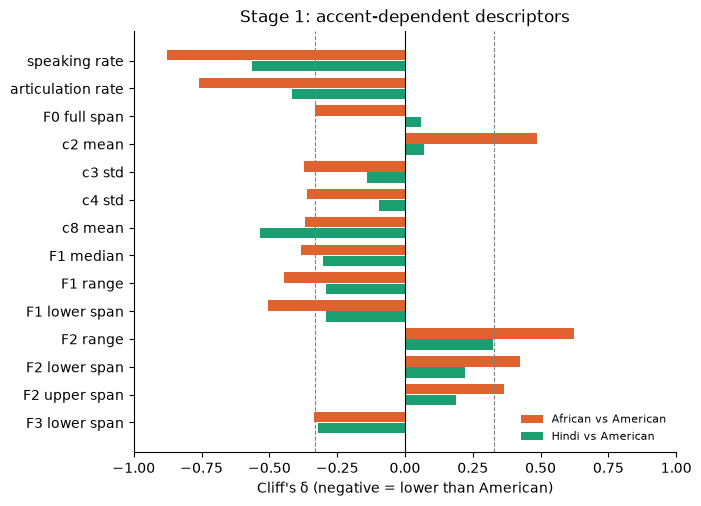

In [11]:
fig, ax = plt.subplots(figsize=(7, 0.32 * len(t1) + 1))
y = np.arange(len(t1))[::-1]
ax.barh(y + 0.2, t1.delta_Af_Am, height=0.38, color=COLORS['African'], label='African vs American')
ax.barh(y - 0.2, t1.delta_Hi_Am, height=0.38, color=COLORS['Hindi'], label='Hindi vs American')
ax.set_yticks(y, t1.descriptor.str.replace('LH ', ''))
for v in (-DELTA_THRESHOLD, DELTA_THRESHOLD): ax.axvline(v, color='grey', ls='--', lw=0.8)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel("Cliff's δ (negative = lower than American)"); ax.set_xlim(-1, 1)
ax.set_title('Stage 1: accent-dependent descriptors'); ax.legend(frameon=False, loc='lower right', fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
savefig(fig, 'fig1_stage1_cliffs_delta.png'); FIGS['stage1'] = fig; plt.show()

## 6. Do the African L1 groups differ from each other?

Kruskal–Wallis tests (the multi-group version of Mann–Whitney) across the five SAA African L1s, and across the three AfriSpeech accents, with Benjamini–Hochberg correction over all descriptors. If nothing differs, African speakers are analysed as one group.


In [12]:
rows = []
for c in X.columns:
    saa_groups = [Z.loc[Af & (d.accent_group == a).values, c] for a in sorted(d[Af].accent_group.unique())]
    as_groups = [Z.loc[AS & (d.accent_group == a).values, c] for a in sorted(d[AS].accent_group.unique())]
    rows.append(dict(descriptor=c, p_SAA_African_L1s=stats.kruskal(*saa_groups).pvalue,
                     p_AfriSpeech_accents=stats.kruskal(*as_groups).pvalue))
L1 = pd.DataFrame(rows)
L1['q_SAA_African_L1s'] = multipletests(L1.p_SAA_African_L1s, method='fdr_bh')[1]
L1['q_AfriSpeech_accents'] = multipletests(L1.p_AfriSpeech_accents, method='fdr_bh')[1]
save(L1, '06_african_L1_differences.csv')
print('SAA African L1 sizes:', d[Af].accent_group.value_counts().to_dict())
print(f'SAA African L1s: descriptors with q < 0.05 = {(L1.q_SAA_African_L1s < Q_THRESHOLD).sum()} (smallest q = {L1.q_SAA_African_L1s.min():.2f})')
print(f'AfriSpeech accents: descriptors with q < 0.05 = {(L1.q_AfriSpeech_accents < Q_THRESHOLD).sum()} (smallest q = {L1.q_AfriSpeech_accents.min():.2f})')
l1 = L1[L1.descriptor.isin(S1[S1.selected].descriptor)].rename(columns={'descriptor': 'Descriptor', 'p_SAA_African_L1s': 'p SAA L1s',
        'q_SAA_African_L1s': 'q SAA L1s', 'p_AfriSpeech_accents': 'p AfriSpeech accents', 'q_AfriSpeech_accents': 'q AfriSpeech accents'})
show(l1[['Descriptor', 'p SAA L1s', 'q SAA L1s', 'p AfriSpeech accents', 'q AfriSpeech accents']],
     'Differences between African L1 groups (selected descriptors)', note='Kruskal–Wallis tests; q = Benjamini–Hochberg across all descriptors.',
     formats={c: '{:.3f}' for c in ['p SAA L1s', 'q SAA L1s', 'p AfriSpeech accents', 'q AfriSpeech accents']})

SAA African L1 sizes: {'amharic': 18, 'hausa': 9, 'kiswahili': 7, 'tigrigna': 7, 'yoruba': 5}
SAA African L1s: descriptors with q < 0.05 = 0 (smallest q = 0.22)
AfriSpeech accents: descriptors with q < 0.05 = 0 (smallest q = 0.19)


Descriptor,p SAA L1s,q SAA L1s,p AfriSpeech accents,q AfriSpeech accents
speaking rate,0.461,0.765,0.132,0.483
articulation rate,0.409,0.765,0.073,0.413
F0 full span,0.136,0.467,0.636,0.908
c2 mean,0.779,0.918,0.743,0.908
c3 std,0.063,0.381,0.249,0.594
c4 std,0.079,0.381,0.456,0.836
c8 mean,0.647,0.812,0.663,0.908
LH F1 median,0.543,0.765,0.944,0.977
LH F1 range,0.805,0.918,0.024,0.278
LH F1 lower span,0.077,0.381,0.448,0.836


<span style="font-size:0.9em">Kruskal–Wallis tests; q = Benjamini–Hochberg across all descriptors.</span>

## 7. Distance from the American baseline, per feature

For each feature, the selected descriptors' z-scores are combined into one **distance** (root-mean-square): **distance = √(mean of z²)**. It measures how far a speaker is from the same-gender American average on that feature, in any direction.

A combined **non-rate distance** (RMS of the pitch, MFCC, F1, F2 and F3 distances, each weighted equally) is used in Section 9.

In [13]:
for f, cols in SEL.items():
    d['dist_' + f] = np.sqrt((Z[cols] ** 2).mean(axis=1))
NONRATE = [f for f in FEATS if f != 'Rate']
d['dist_NonRate'] = np.sqrt((d[['dist_' + f for f in NONRATE]] ** 2).mean(axis=1))

dist_summary = d.groupby('group')[['dist_' + f for f in FEATS + ['NonRate']]].median().reindex(GROUPS)
dist_summary.columns = [c.replace('dist_', '') for c in dist_summary.columns]
show(dist_summary, 'Median distance from the American baseline per group (z units)', index=True, formats='{:.2f}')
save(dist_summary, '07_median_distance_by_group.csv', index=True)

,Rate,Pitch,MFCC,F1,F2,F3,NonRate
group,,,,,,,
American,0.69,0.56,0.86,0.74,0.79,0.71,0.87
Hindi,1.14,0.34,1.03,0.86,1.10,0.68,0.99
African,2.09,0.80,1.10,0.95,1.20,0.89,1.11
AfriSpeech,1.36,0.70,1.45,1.01,1.47,0.96,1.29


## 8. Stage 2: does distance from the baseline relate to WER?

Within each group, **Spearman's ρ** between each feature's distance and WER (ranks, so the many zero WERs and a few very high WERs don't dominate). The p-value comes directly from `spearmanr`. The **95% confidence interval** comes from a percentile bootstrap (speakers resampled with replacement). p-values are corrected across the six features **within each group** (Benjamini–Hochberg).

- **African** (SAA): main result.
- **American** and **Hindi** (SAA): does the same hold for other accent groups?
- **AfriSpeech**: does it replicate in a second corpus? (Different text and recording conditions: see the note below the table.)

In [14]:
rng = np.random.default_rng(SEED)
def spearman_ci(x, y, B=N_BOOT):
    x, y = np.asarray(x), np.asarray(y); n = len(x)
    r, p = stats.spearmanr(x, y)
    boot = [stats.spearmanr(x[i], y[i])[0] for i in (rng.integers(0, n, n) for _ in range(B))]
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return r, p, lo, hi

rows = []
for g in GROUPS:
    m = MASK[g]
    for f in FEATS + ['NonRate']:
        r, p, lo, hi = spearman_ci(d.loc[m, 'dist_' + f], W[m])
        rows.append(dict(group=g, feature=f, n=int(m.sum()), rho=r, ci_low=lo, ci_high=hi, p=p))
S2 = pd.DataFrame(rows); S2['q'] = np.nan
for g in GROUPS:
    k = (S2.group == g) & (S2.feature != 'NonRate')      # correct across the six features
    S2.loc[k, 'q'] = multipletests(S2.loc[k, 'p'], method='fdr_bh')[1]
save(S2, '08_stage2_distance_vs_wer.csv')

def fmt(r):
    star = '*' if r.q < Q_THRESHOLD else ('†' if r.p < 0.05 else '')
    return f'{r.rho:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]{star}'
table2 = S2[S2.feature != 'NonRate'].assign(v=lambda t: t.apply(fmt, axis=1)).pivot(index='feature', columns='group', values='v').loc[FEATS, GROUPS]
table2.columns = [f'{g} (n={MASK[g].sum()})' for g in GROUPS]
save(table2, 'TABLE2_stage2_distance_vs_wer.csv', index=True)
show(table2, 'TABLE II. Spearman correlation between distance from the American baseline and WER', index=True,
     note='ρ [95% bootstrap CI]. * q < 0.05 (Benjamini–Hochberg across the six features within each group); † p < 0.05 before correction only.')

,American (n=306),Hindi (n=18),African (n=46),AfriSpeech (n=165)
feature,,,,
Rate,"+0.16 [+0.04, +0.26]*","+0.13 [-0.35, +0.52]","+0.66 [+0.45, +0.81]*","+0.21 [+0.06, +0.34]*"
Pitch,"+0.07 [-0.04, +0.19]","+0.17 [-0.33, +0.62]","+0.33 [+0.04, +0.61]†","+0.04 [-0.11, +0.19]"
MFCC,"+0.15 [+0.04, +0.26]*","-0.00 [-0.52, +0.46]","+0.25 [-0.05, +0.53]","+0.13 [-0.04, +0.28]"
F1,"+0.12 [+0.01, +0.23]†","-0.06 [-0.59, +0.51]","+0.05 [-0.25, +0.34]","+0.10 [-0.06, +0.26]"
F2,"+0.07 [-0.05, +0.17]","-0.19 [-0.65, +0.32]","-0.04 [-0.37, +0.28]","+0.02 [-0.14, +0.18]"
F3,"-0.01 [-0.13, +0.10]","-0.06 [-0.55, +0.42]","+0.03 [-0.26, +0.34]","-0.08 [-0.25, +0.07]"


<span style="font-size:0.9em">ρ [95% bootstrap CI]. * q < 0.05 (Benjamini–Hochberg across the six features within each group); † p < 0.05 before correction only.</span>

**Why AfriSpeech is only a partial replication**: each AfriSpeech speaker reads different, often medical, text; recordings come from many different devices; and distances are measured against SAA American speakers recorded under SAA conditions. The cell below shows the effect of content and recording conditions directly: the **same accents** (Yoruba, Kiswahili, Hausa) get very different WER and distances in the two corpora.

In [15]:
same3 = d[d.accent_group.isin(['yoruba', 'kiswahili', 'hausa'])]
same_acc = same3.groupby(['accent_group', 'dataset']).wer.mean().unstack() * 100
show(same_acc, 'Mean WER (%) for the same accents in each corpus', index=True, formats='{:.1f}')
same_dist = same3.groupby('dataset')[['dist_' + f for f in FEATS]].median()
same_dist.columns = [c.replace('dist_', '') for c in same_dist.columns]
show(same_dist, 'Median distance from the American baseline for the same accents in each corpus', index=True, formats='{:.2f}')
save(same_acc, '08_same_accent_wer_by_corpus.csv', index=True); save(same_dist, '08_same_accent_distance_by_corpus.csv', index=True)

dataset,afrispeech,saa
accent_group,,
hausa,49.2,8.9
kiswahili,31.8,11.4
yoruba,50.5,13.3


,Rate,Pitch,MFCC,F1,F2,F3
dataset,,,,,,
afrispeech,1.36,0.70,1.45,1.01,1.47,0.96
saa,2.06,0.57,1.09,0.98,1.18,0.89


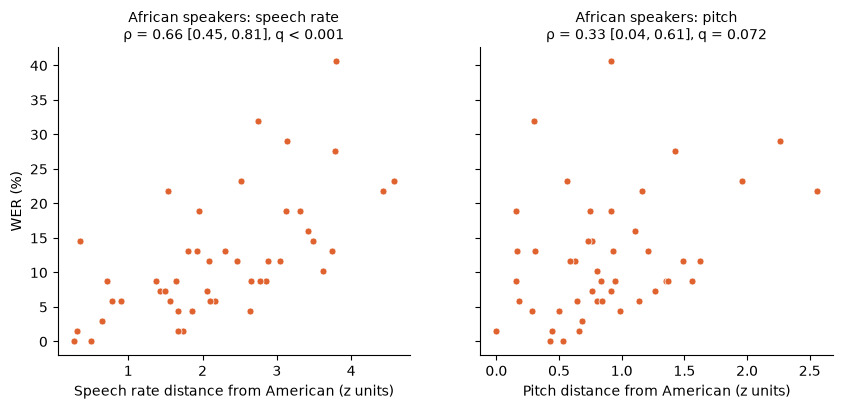

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, f, title in [(axes[0], 'Rate', 'Speech rate'), (axes[1], 'Pitch', 'Pitch')]:
    if f not in FEATS: ax.set_visible(False); continue
    x, y = d.loc[Af, 'dist_' + f], 100 * W[Af]
    r = S2[(S2.group == 'African') & (S2.feature == f)].iloc[0]
    ax.scatter(x, y, color=COLORS['African'], s=25, edgecolor='white', lw=0.5)
    ax.set_xlabel(f'{title} distance from American (z units)')
    qtxt = '< 0.001' if r.q < 0.001 else f'= {r.q:.3f}'
    ax.set_title(f'African speakers: {title.lower()}\nρ = {r.rho:.2f} [{r.ci_low:.2f}, {r.ci_high:.2f}], q {qtxt}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('WER (%)')
savefig(fig, 'fig2_african_distance_vs_wer.png'); FIGS['scatter'] = fig; plt.show()

## 9. Speech rate vs everything else: share of WER explained

Speaker ranks of WER are predicted from the rank of (a) speech-rate distance, (b) non-rate distance, and (c) both together, by least-squares regression. **R²** is the share of variation in WER rank that the prediction removes.

- Unique to rate = R²(both) − R²(non-rate)
- Unique to non-rate = R²(both) − R²(rate)
- Shared = R²(rate) + R²(non-rate) − R²(both)

The **added-value p-values** come from the two-predictor model: "does this predictor add anything beyond the other?"

In [17]:
def r2(mask, cols):
    R = d.loc[mask, ['wer'] + cols].rank()
    A = np.column_stack([np.ones(len(R))] + [R[c] for c in cols])
    b = np.linalg.lstsq(A, R.wer, rcond=None)[0]
    return 1 - np.var(R.wer - A @ b) / np.var(R.wer)

rows = []
for g in GROUPS:
    m = MASK[g]
    a, b, c = r2(m, ['dist_Rate']), r2(m, ['dist_NonRate']), r2(m, ['dist_Rate', 'dist_NonRate'])
    fit = smf.ols('wer ~ dist_Rate + dist_NonRate', data=d.loc[m, ['wer', 'dist_Rate', 'dist_NonRate']].rank()).fit()
    rows.append(dict(group=g, n=int(m.sum()),
                     rate_alone=a, nonrate_alone=b, both=c, unique_rate=c - b, shared=a + b - c, unique_nonrate=c - a,
                     p_rate_alone=stats.spearmanr(d.loc[m, 'dist_Rate'], W[m])[1],
                     p_nonrate_alone=stats.spearmanr(d.loc[m, 'dist_NonRate'], W[m])[1],
                     p_rate_added=fit.pvalues['dist_Rate'], p_nonrate_added=fit.pvalues['dist_NonRate'],
                     rho_rate_vs_nonrate=stats.spearmanr(d.loc[m, 'dist_Rate'], d.loc[m, 'dist_NonRate'])[0]))
VS = pd.DataFrame(rows); save(VS, '09_rate_vs_nonrate.csv')

table3 = VS[['group', 'n']].copy()
for c in ['rate_alone', 'nonrate_alone', 'both', 'unique_rate', 'shared', 'unique_nonrate']:
    table3[c + ' (%)'] = (100 * VS[c]).round(1)
table3['p non-rate adds beyond rate'] = VS.p_nonrate_added.map(pfmt)
table3['p rate adds beyond non-rate'] = VS.p_rate_added.map(pfmt)
save(table3, 'TABLE3_rate_vs_nonrate.csv')
t3 = table3.rename(columns={'group': 'Group', 'rate_alone (%)': 'Rate alone (%)', 'nonrate_alone (%)': 'Non-rate alone (%)', 'both (%)': 'Both (%)',
                            'unique_rate (%)': 'Unique to rate (%)', 'shared (%)': 'Shared (%)', 'unique_nonrate (%)': 'Unique to non-rate (%)'})
show(t3, 'TABLE III. Share of variation in WER rank explained by speech-rate and non-rate distance',
     note='R² from least-squares regression on ranks. p-values test whether each predictor adds information beyond the other. A slightly negative shared value means no overlap (read as ≈0).',
     formats={c: '{:.1f}' for c in t3.columns if '(%)' in c})

Group,n,Rate alone (%),Non-rate alone (%),Both (%),Unique to rate (%),Shared (%),Unique to non-rate (%),p non-rate adds beyond rate,p rate adds beyond non-rate
American,306,2.5,1.5,4.1,2.6,-0.1,1.6,0.025,0.005
Hindi,18,1.8,0.5,2.4,1.9,-0.1,0.6,0.766,0.597
African,46,43.7,6.7,44.5,37.8,5.9,0.8,0.438,<0.001
AfriSpeech,165,4.2,0.8,4.5,3.8,0.4,0.3,0.470,0.012


<span style="font-size:0.9em">R² from least-squares regression on ranks. p-values test whether each predictor adds information beyond the other. A slightly negative shared value means no overlap (read as ≈0).</span>

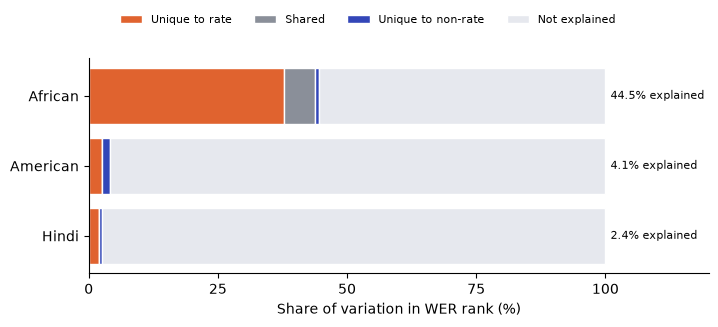

In [18]:
fig, ax = plt.subplots(figsize=(8, 2.8))
labels = ['Unique to rate', 'Shared', 'Unique to non-rate', 'Not explained']
cols_ = [COLORS['African'], '#8a8f99', '#3346b8', '#e6e8ee']
for i, g in enumerate(['African', 'American', 'Hindi']):
    r = VS[VS.group == g].iloc[0]
    parts = [r.unique_rate, max(r.shared, 0), r.unique_nonrate]; parts.append(1 - sum(parts))
    left = 0
    for v, col, lab in zip(parts, cols_, labels):
        ax.barh(i, 100 * v, left=left, color=col, edgecolor='white', label=lab if i == 0 else None); left += 100 * v
    ax.text(101, i, f'{100 * r.both:.1f}% explained', va='center', fontsize=8)
ax.set_yticks(range(3), ['African', 'American', 'Hindi']); ax.invert_yaxis()
ax.set_xlim(0, 120); ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xlabel('Share of variation in WER rank (%)')
ax.legend(ncol=4, frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.45, 1.25))
ax.spines[['top', 'right']].set_visible(False)
savefig(fig, 'fig3_rate_vs_nonrate.png'); FIGS['rate_vs_nonrate'] = fig; plt.show()

## 10. Same speaking rate, different WER?

If speech rate explained the African–American WER gap, African and American speakers who read at the **same pace** should have similar WER. Speakers are matched by their speaking-rate z-score (vs same-gender Americans), and WER is compared within each band with a Mann–Whitney test and Cliff's δ. Several bands are used to show the result does not depend on the band chosen.

In [19]:
z_rate = Z['speaking rate'].values
rows = []
for lo, hi in RATE_BANDS:
    band = SAA & (z_rate > lo) & (z_rate < hi)
    a, b, h = band & Af, band & Am, band & Hi
    dl, p = cliff(W[a], W[b])
    rows.append(dict(band=f'{lo} to {hi}', n_African=int(a.sum()), n_American=int(b.sum()), n_Hindi=int(h.sum()),
                     WER_African_pct=100 * W[a].mean(), WER_American_pct=100 * W[b].mean(),
                     WER_Hindi_pct=100 * W[h].mean() if h.any() else np.nan, ratio_Af_Am=W[a].mean() / W[b].mean(),
                     cliffs_delta_Af_Am=dl, p_Af_Am=p,
                     median_rate_z_African=np.median(z_rate[a]), median_rate_z_American=np.median(z_rate[b])))
SR = pd.DataFrame(rows); save(SR, 'TABLE4_same_speaking_rate.csv')
t4 = SR.rename(columns={'band': 'Speaking-rate z band', 'n_African': 'n African', 'n_American': 'n American', 'n_Hindi': 'n Hindi',
                        'WER_African_pct': 'WER African (%)', 'WER_American_pct': 'WER American (%)', 'WER_Hindi_pct': 'WER Hindi (%)',
                        'ratio_Af_Am': 'Ratio Af/Am', 'cliffs_delta_Af_Am': 'δ Af–Am', 'p_Af_Am': 'p Af–Am',
                        'median_rate_z_African': 'Median rate z (Af)', 'median_rate_z_American': 'Median rate z (Am)'})
show(t4, 'TABLE IV. WER of speakers with similar speaking rates',
     note="Mann–Whitney test and Cliff's δ for African vs American WER within each band.",
     formats={'WER African (%)': '{:.1f}', 'WER American (%)': '{:.1f}', 'WER Hindi (%)': '{:.1f}', 'Ratio Af/Am': '{:.1f}',
              'δ Af–Am': '{:+.2f}', 'p Af–Am': pfmt, 'Median rate z (Af)': '{:.2f}', 'Median rate z (Am)': '{:.2f}'})

Speaking-rate z band,n African,n American,n Hindi,WER African (%),WER American (%),WER Hindi (%),Ratio Af/Am,δ Af–Am,p Af–Am,Median rate z (Af),Median rate z (Am)
-2.5 to -0.5,24,82,11,8.2,2.1,2.5,3.9,+0.73,<0.001,-1.85,-1.06
-2.0 to -1.0,12,42,6,8.0,2.3,1.7,3.4,+0.80,<0.001,-1.65,-1.36
-2.5 to -1.5,17,18,5,8.4,3.5,1.7,2.4,+0.60,0.002,-2.01,-1.84
-1.8 to -0.8,8,49,7,7.6,1.8,3.3,4.2,+0.77,<0.001,-1.29,-1.11


<span style="font-size:0.9em">Mann–Whitney test and Cliff's δ for African vs American WER within each band.</span>

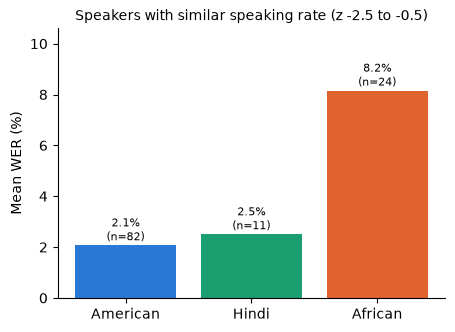

In [20]:
r0 = SR.iloc[0]; lo, hi = RATE_BANDS[0]
fig, ax = plt.subplots(figsize=(5, 3.5))
vals = [r0.WER_American_pct, r0.WER_Hindi_pct, r0.WER_African_pct]
ns = [r0.n_American, r0.n_Hindi, r0.n_African]
ax.bar(['American', 'Hindi', 'African'], vals, color=[COLORS['American'], COLORS['Hindi'], COLORS['African']])
for i, (v, n) in enumerate(zip(vals, ns)): ax.text(i, v + 0.2, f'{v:.1f}%\n(n={n})', ha='center', fontsize=8)
ax.set_ylabel('Mean WER (%)'); ax.set_title(f'Speakers with similar speaking rate (z {lo} to {hi})', fontsize=10)
ax.spines[['top', 'right']].set_visible(False); ax.set_ylim(0, max(vals) * 1.3)
savefig(fig, 'fig4_same_speaking_rate.png'); FIGS['same_rate'] = fig; plt.show()

## Direction of each selected descriptor vs WER

Spearman's ρ between each descriptor's **signed** z-score and WER (raw sign: a negative ρ means *lower* values go with *higher* WER, e.g. slower speech → more errors). Corrected across the selected descriptors within each group. With this many tests, only starred results should be treated as reliable.

In [21]:
rows = []
for f, cols in SEL.items():
    for c in cols:
        delta = S1.loc[S1.descriptor == c, 'delta_Af_Am'].iloc[0]
        r = dict(feature=f, descriptor=c, African_vs_American='lower' if delta < 0 else 'higher')
        for g in GROUPS:
            m = MASK[g]; rr = stats.spearmanr(Z.loc[m, c], W[m])
            r[f'rho_{g}'], r[f'p_{g}'] = rr[0], rr[1]
        rows.append(r)
DIR = pd.DataFrame(rows)
for g in GROUPS: DIR[f'q_{g}'] = multipletests(DIR[f'p_{g}'], method='fdr_bh')[1]
save(DIR, 'APPENDIX_A1_direction.csv')
tableA1 = DIR[['feature', 'descriptor', 'African_vs_American']].copy()
for g in GROUPS:
    tableA1[g] = [f"{r[f'rho_{g}']:+.2f}" + ('*' if r[f'q_{g}'] < Q_THRESHOLD else ('†' if r[f'p_{g}'] < 0.05 else '')) for _, r in DIR.iterrows()]
save(tableA1, 'APPENDIX_A1_direction_table.csv')
tA1 = tableA1.rename(columns={'feature': 'Feature', 'descriptor': 'Descriptor', 'African_vs_American': 'African vs American'})
tA1['Descriptor'] = tA1['Descriptor'].str.replace('LH ', '')
show(tA1, 'Appendix table: direction of each selected descriptor vs WER (Spearman ρ, signed z-score)',
     note='Negative ρ = lower values go with higher WER. * q < 0.05 (Benjamini–Hochberg across descriptors within each group); † p < 0.05 before correction only.')

Feature,Descriptor,African vs American,American,Hindi,African,AfriSpeech
Rate,speaking rate,lower,-0.01,+0.01,-0.66*,-0.25*
Rate,articulation rate,lower,-0.02,+0.11,-0.60*,-0.23*
Pitch,F0 full span,lower,-0.06,+0.06,-0.06,+0.12
MFCC,c2 mean,higher,+0.15*,-0.37,+0.13,+0.09
MFCC,c3 std,lower,-0.16*,+0.38,-0.30†,-0.01
MFCC,c4 std,lower,-0.16*,+0.38,-0.23,+0.04
MFCC,c8 mean,lower,-0.06,+0.15,+0.08,+0.01
F1,F1 median,lower,-0.11,-0.17,-0.01,-0.06
F1,F1 range,lower,-0.18*,+0.16,-0.32†,+0.05
F1,F1 lower span,lower,-0.10,+0.25,-0.08,-0.01


<span style="font-size:0.9em">Negative ρ = lower values go with higher WER. * q < 0.05 (Benjamini–Hochberg across descriptors within each group); † p < 0.05 before correction only.</span>

## Pooled SAA, accounting for accent group

All SAA speakers (American, Hindi, African) pooled, but each speaker is only compared with others in their own group: the ranks of distance and WER are adjusted for group membership (African and Hindi indicator variables) and the leftovers are correlated (partial Spearman). This asks whether people who differ more get more errors **beyond** the group-level gap.

In [22]:
def partial_spearman(x, y, covars):
    R = pd.DataFrame(np.column_stack([x, y, covars])).rank().values
    A = np.column_stack([np.ones(len(R)), R[:, 2:]])
    rx = R[:, 0] - A @ np.linalg.lstsq(A, R[:, 0], rcond=None)[0]
    ry = R[:, 1] - A @ np.linalg.lstsq(A, R[:, 1], rcond=None)[0]
    return stats.pearsonr(rx, ry)

saa3 = SAA & (Am | Hi | Af)
covars = np.column_stack([G[saa3] == 'African', G[saa3] == 'Hindi']).astype(float)
rows = []
for f in FEATS:
    r, p = partial_spearman(d.loc[saa3, 'dist_' + f].values, W[saa3], covars)
    rows.append(dict(feature=f, n=int(saa3.sum()), rho=r, p=p))
A2 = pd.DataFrame(rows); A2['q'] = multipletests(A2.p, method='fdr_bh')[1]
save(A2, 'APPENDIX_A2_accounting_for_group.csv')
show(A2.rename(columns={'feature': 'Feature', 'rho': 'Partial ρ', 'p': 'p', 'q': 'q'}),
     'Appendix table: pooled SAA correlation between distance and WER, accounting for accent group',
     note='Partial Spearman correlation adjusting for African and Hindi group membership. q = Benjamini–Hochberg across the six features.',
     formats={'Partial ρ': '{:+.2f}', 'p': pfmt, 'q': pfmt})

Feature,n,Partial ρ,p,q
Rate,370,+0.20,<0.001,<0.001
Pitch,370,+0.10,0.046,0.070
MFCC,370,+0.15,0.004,0.011
F1,370,+0.11,0.037,0.070
F2,370,+0.04,0.425,0.510
F3,370,-0.00,0.960,0.960


<span style="font-size:0.9em">Partial Spearman correlation adjusting for African and Hindi group membership. q = Benjamini–Hochberg across the six features.</span>